In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
#Load the dataset
data = load_breast_cancer()

df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

print("First five rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDescriptive statistics:")
print(df.describe())

print("\nData types:")
print(df.dtypes)

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area 

In [ ]:
#Check missing values and target distribution
print("Missing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["target"].value_counts())

print("\nTarget names:")
print(data.target_names)

print("\nCategorical columns:")
print(df.select_dtypes(include="object").columns.tolist())

print("\nNumerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

Missing values:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Target distribution:
target
1    357
0    212
Name: count, dtype: int64

In [ ]:
#Split the dataset
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


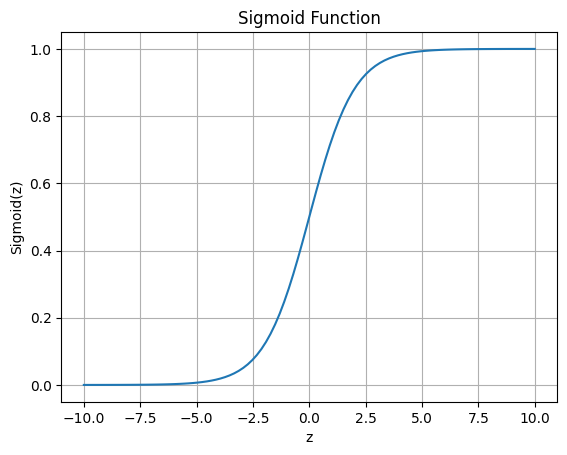

In [ ]:
#Implement the sigmoid function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

z = np.linspace(-10, 10, 100)
probabilities = sigmoid(z)

plt.plot(z, probabilities)
plt.title("Sigmoid Function")
plt.xlabel("z")
plt.ylabel("Sigmoid(z)")
plt.grid(True)
plt.show()

In [ ]:
#Train the basic logistic regression model
log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

log_model.fit(X_train, y_train)

y_train_pred = log_model.predict(X_train)
y_test_pred = log_model.predict(X_test)

print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))

Training Accuracy: 0.989010989010989
Testing Accuracy: 0.9824561403508771


Accuracy: 0.9824561403508771
Precision: 0.9861111111111112
Recall: 0.9861111111111112
F1 Score: 0.9861111111111112


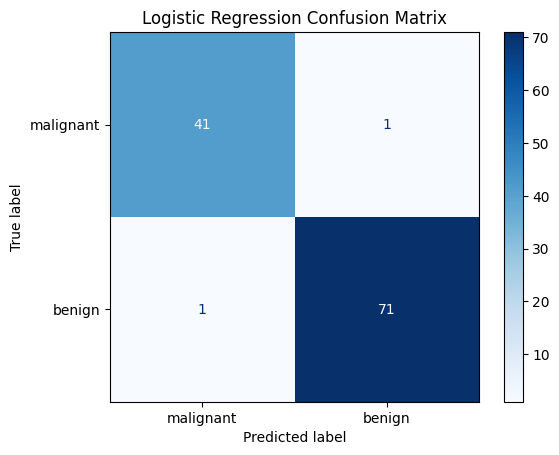

In [ ]:
#Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 Score:", f1_score(y_test, y_test_pred))

cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

Lasso Accuracy: 0.9912280701754386
Lasso Precision: 0.9863013698630136
Lasso Recall: 1.0
Lasso F1 Score: 0.993103448275862


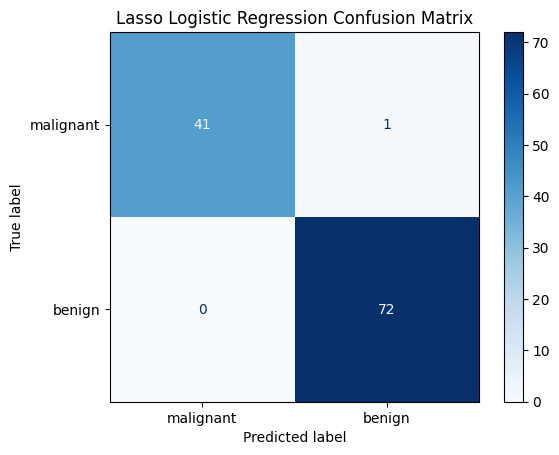

In [ ]:
#Apply Lasso regularization (L1)
lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=1.0,
        max_iter=1000,
        random_state=42
    ))
])

lasso_model.fit(X_train, y_train)

y_lasso_pred = lasso_model.predict(X_test)

print("Lasso Accuracy:", accuracy_score(y_test, y_lasso_pred))
print("Lasso Precision:", precision_score(y_test, y_lasso_pred))
print("Lasso Recall:", recall_score(y_test, y_lasso_pred))
print("Lasso F1 Score:", f1_score(y_test, y_lasso_pred))

cm_lasso = confusion_matrix(y_test, y_lasso_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lasso,
    display_labels=data.target_names
).plot(cmap="Blues")

plt.title("Lasso Logistic Regression Confusion Matrix")
plt.show()

In [ ]:
#Display the Lasso coefficient table
lasso_coefficients = lasso_model.named_steps["model"].coef_[0]

lasso_table = pd.DataFrame({
    "feature": X.columns,
    "coefficient": lasso_coefficients
})

print(lasso_table)

print("\nNumber of zero coefficients:",
      np.sum(lasso_coefficients == 0))

print("Number of non-zero coefficients:",
      np.sum(lasso_coefficients != 0))

                    feature  coefficient
0               mean radius     0.000000
1              mean texture    -0.397179
2            mean perimeter     0.000000
3                 mean area     0.000000
4           mean smoothness     0.000000
5          mean compactness     0.000000
6            mean concavity     0.000000
7       mean concave points    -0.489200
8             mean symmetry     0.000000
9    mean fractal dimension     0.080631
10             radius error    -2.167842
11            texture error     0.024568
12          perimeter error     0.000000
13               area error     0.000000
14         smoothness error    -0.198856
15        compactness error     0.698341
16          concavity error     0.000000
17     concave points error    -0.072610
18           symmetry error     0.000000
19  fractal dimension error     0.190994
20             worst radius    -1.248721
21            worst texture    -1.205456
22          worst perimeter     0.000000
23              

Ridge Accuracy: 0.9824561403508771
Ridge Precision: 0.9861111111111112
Ridge Recall: 0.9861111111111112
Ridge F1 Score: 0.9861111111111112


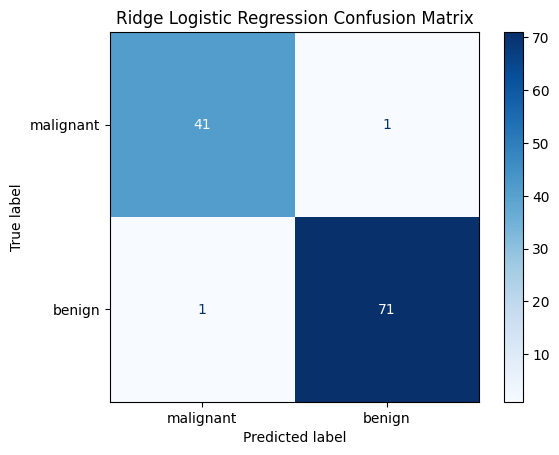

In [ ]:

#Apply Ridge regularization (L2)
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="l2",
        C=1.0,
        max_iter=1000,
        random_state=42
    ))
])

ridge_model.fit(X_train, y_train)

y_ridge_pred = ridge_model.predict(X_test)

print("Ridge Accuracy:", accuracy_score(y_test, y_ridge_pred))
print("Ridge Precision:", precision_score(y_test, y_ridge_pred))
print("Ridge Recall:", recall_score(y_test, y_ridge_pred))
print("Ridge F1 Score:", f1_score(y_test, y_ridge_pred))

cm_ridge = confusion_matrix(y_test, y_ridge_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm_ridge,
    display_labels=data.target_names
).plot(cmap="Blues")

plt.title("Ridge Logistic Regression Confusion Matrix")
plt.show()

In [ ]:
#Display the Ridge coefficient table
ridge_coefficients = ridge_model.named_steps["model"].coef_[0]

ridge_table = pd.DataFrame({
    "feature": X.columns,
    "coefficient": ridge_coefficients
})

print(ridge_table)

                    feature  coefficient
0               mean radius    -0.511479
1              mean texture    -0.552698
2            mean perimeter    -0.476298
3                 mean area    -0.541059
4           mean smoothness    -0.212479
5          mean compactness     0.648342
6            mean concavity    -0.602103
7       mean concave points    -0.704156
8             mean symmetry    -0.167233
9    mean fractal dimension     0.199732
10             radius error    -1.082965
11            texture error     0.248823
12          perimeter error    -0.544333
13               area error    -0.929104
14         smoothness error    -0.160276
15        compactness error     0.647227
16          concavity error     0.160563
17     concave points error    -0.443784
18           symmetry error     0.360492
19  fractal dimension error     0.437894
20             worst radius    -0.947616
21            worst texture    -1.255088
22          worst perimeter    -0.763220
23              

In [ ]:
#Compare all three models
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Lasso (L1)", "Ridge (L2)"],
    "Accuracy": [
        accuracy_score(y_test, y_test_pred),
        accuracy_score(y_test, y_lasso_pred),
        accuracy_score(y_test, y_ridge_pred)
    ],
    "Precision": [
        precision_score(y_test, y_test_pred),
        precision_score(y_test, y_lasso_pred),
        precision_score(y_test, y_ridge_pred)
    ],
    "Recall": [
        recall_score(y_test, y_test_pred),
        recall_score(y_test, y_lasso_pred),
        recall_score(y_test, y_ridge_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_test_pred),
        f1_score(y_test, y_lasso_pred),
        f1_score(y_test, y_ridge_pred)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.982456   0.986111  0.986111  0.986111
1           Lasso (L1)  0.991228   0.986301  1.000000  0.993103
2           Ridge (L2)  0.982456   0.986111  0.986111  0.986111


In [ ]:
models = {
    "Logistic Regression": log_model,
    "Lasso (L1)": lasso_model,
    "Ridge (L2)": ridge_model
}

for name, model in models.items():
    scores = cross_val_score(
        model, X, y,
        cv=5,
        scoring="accuracy"
    )

    print("\n", name)
    print("Fold accuracies:", scores)
    print("Mean accuracy:", scores.mean())


 Logistic Regression
Fold accuracies: [0.98245614 0.98245614 0.97368421 0.97368421 0.99115044]
Mean accuracy: 0.9806862288464524

 Lasso (L1)
Fold accuracies: [0.96491228 0.96491228 0.95614035 0.97368421 0.99115044]
Mean accuracy: 0.9701599130569788

 Ridge (L2)
Fold accuracies: [0.98245614 0.98245614 0.97368421 0.97368421 0.99115044]
Mean accuracy: 0.9806862288464524


In [ ]:
#Five-fold cross-validation
for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    print("\n", name)
    print("Cross-validation scores:", scores)
    print("Mean accuracy:", scores.mean())


 Logistic Regression
Cross-validation scores: [0.96703297 0.97802198 0.96703297 1.         0.98901099]
Mean accuracy: 0.9802197802197803

 Lasso (L1)
Cross-validation scores: [0.95604396 0.97802198 0.96703297 0.98901099 0.98901099]
Mean accuracy: 0.9758241758241759

 Ridge (L2)
Cross-validation scores: [0.96703297 0.97802198 0.96703297 1.         0.98901099]
Mean accuracy: 0.9802197802197803


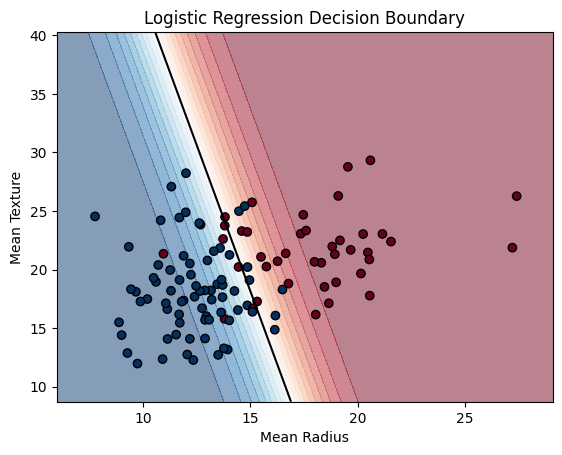

In [ ]:
#Plot the decision boundary
features = ["mean radius", "mean texture"]

X_2d = df[features]
y_2d = df["target"]

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

boundary_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

boundary_model.fit(X_train_2d, y_train_2d)

x_min, x_max = X_2d.iloc[:, 0].min() - 1, X_2d.iloc[:, 0].max() + 1
y_min, y_max = X_2d.iloc[:, 1].min() - 1, X_2d.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame({
    "mean radius": xx.ravel(),
    "mean texture": yy.ravel()
})

Z = boundary_model.predict_proba(grid)[:, 1]
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, levels=20, cmap="RdBu", alpha=0.5)
plt.contour(xx, yy, Z, levels=[0.5], colors="black")

plt.scatter(
    X_test_2d["mean radius"],
    X_test_2d["mean texture"],
    c=y_test_2d,
    cmap="RdBu",
    edgecolors="black"
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Logistic Regression Decision Boundary")
plt.show()